# Supplementary figures for Figure 3b — expression, constraint and lineage depth

Do the genes whose tissue-specific isoform is confined to one lineage differ, in expression or in selective constraint, from those whose isoform is shared across all animals?

Four independent figures:

| figure | content |
|---|---|
| `SFigure3_expression_human` | GTEx v8 median TPM vs. the human-referenced lineage categories |
| `SFigure3_expression_mouse` | Mazin *et al.* median TPM per tissue vs. the mouse-referenced categories |
| `SFigure3_expression_summary` | both species side by side, effect sizes only |
| `SFigure3_expression_constraint` | gnomAD v4.1.2 pLI and LOEUF, and their interaction with expression |

All numbers come from `prepare_sfig3_expression.py`; this notebook only draws.

In [1]:
import os
import pickle

import numpy as np
import pandas as pd
import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

FIG_DIR  = '/project2/yangili1/cfbuenabadn/torino_paper/notebooks/Figure3'
DATA_PKL = os.path.join(FIG_DIR, 'figure_data', 'sfig3_expression.pkl')

mpl.rcParams.update({
    'pdf.fonttype':      42,      # embed TrueType, not Type 3
    'ps.fonttype':       42,
    # 'none' keeps text as real <text> elements with one x for the whole string,
    # so Inkscape can edit the labels instead of piling glyphs up in one spot.
    'svg.fonttype':      'none',
    'font.family':       'sans-serif',
    'font.sans-serif':   ['DejaVu Sans'],
    'axes.linewidth':    0.5,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size':  1.6,
    'ytick.major.size':  1.6,
    'savefig.dpi':       400,
})

## Page plan

Geometry in millimetres from a top-left origin. Each figure sets its own `PAGE['h']` from its vertical plan, so a changed gutter or row height propagates instead of silently pushing a label off the sheet.

In [2]:
# ----------------------------------------------------------------------------
# Geometry in millimetres from a top-left origin.  Each figure sets PAGE_H
# from its own vertical plan, so `rect()` reads the current page through a
# module-level dict rather than a constant.
# ----------------------------------------------------------------------------
PAGE_W   = 180.0
MARGIN_L = 2.0
MARGIN_R = 2.0
MARGIN_T = 1.0
MARGIN_B = 2.0

CONTENT_W = PAGE_W - MARGIN_L - MARGIN_R

TITLE_H   = 12.0      # figure title + three subtitle lines
SUB_LINE  = 2.3       # subtitle line pitch
LETTER_H  = 7.5       # panel letter, panel title and the group-size row
ROW_GAP   = 4.0
COL_GAP   = 9.0
GUTTER_L  = 11.0      # y-axis label + tick labels, left of every axes
ROW_FOOT  = 8.5       # rotated x ticks + x-axis label, below every axes
EDGE_SLACK = 3.0      # keeps the right-most tick label on the page

# Typography — Nature Genetics floor is 5 pt
FS_PANEL = 8.0        # bold panel letters
FS_TITLE = 7.0        # figure title
FS_SUB   = 6.0        # panel titles
FS_TICK  = 5.0
FS_LABEL = 5.5
FS_ANNOT = 5.0
FS_SMALL = 4.6        # dense tick columns

TITLE_PAD   = 2.0     # pt, panel title above the axes
TITLE_PAD_N = 7.5     # pt, where a row of group sizes sits in between

PAGE = {'h': 100.0}   # overwritten per figure


def rect(x, y, w, h):
    """mm box (top-left origin) -> [left, bottom, width, height] figure fractions."""
    return [x / PAGE_W, 1.0 - (y + h) / PAGE['h'], w / PAGE_W, h / PAGE['h']]


def add_ax(fig, x, y, w, h, **kw):
    ax = fig.add_axes(rect(x, y, w, h), **kw)
    ax.tick_params(labelsize=FS_TICK, pad=1.2)
    ax.spines[['top', 'right']].set_visible(False)
    return ax


def panel_letter(fig, letter, x, y):
    fig.text(x / PAGE_W, 1.0 - y / PAGE['h'], letter,
             fontsize=FS_PANEL, fontweight='bold', va='top', ha='left')


def fig_text(fig, x, y, s, **kw):
    return fig.text(x / PAGE_W, 1.0 - y / PAGE['h'], s, **kw)


def new_page(height_mm):
    PAGE['h'] = height_mm
    return plt.figure(figsize=(PAGE_W / 25.4, height_mm / 25.4))

## Palettes

The conservation ramp runs shallow (lineage-restricted) → deep (pan-vertebrate). It is sequential rather than categorical because the variable is ordered.

Tissue classes keep their Figure 3b colours. Figure 3b gives brain and cerebellum the same yellow and separates them by stacking order, which a line plot cannot do — dash patterns carry that distinction here.

In [3]:
# One ramp per species, shallow (lineage-restricted) -> deep (pan-vertebrate).
# Sequential rather than categorical: the variable is ordered, and the ramp
# makes the ordering readable without a key.
CONS_COLORS = {
    'human': ['#FDD49E', '#FDBB84', '#E34A33', '#99000D'],
    'mouse': ['#FDD49E', '#FDBB84', '#FC8D59', '#E34A33', '#99000D'],
}

# Short axis labels; the full category names are spelled out in the title.
CONS_SHORT = {
    'Human only':  'Human',
    'Mouse only':  'Mouse',
    'Primates':    'Primates',
    'Rodents':     'Rodents',
    'Gilres':      'Gilres',
    'Mammals':     'Mammals',
    'All animals': 'All species',
}

# Figure 3B tissue rows, with the colours that panel already uses for them
TISSUE_ROWS = ['Brain only', 'Cerebellum only', 'Brain & Cerebellum only',
               'Liver only', 'Heart only', 'Testis only', 'Multiple tissues']
ROW_COLORS = {
    'Brain only':              '#EEEE00',
    'Cerebellum only':         '#EEEE00',
    'Brain & Cerebellum only': '#CCCC00',
    'Liver only':              '#CDB79E',
    'Heart only':              '#B452CD',
    'Testis only':             '#A6A6A6',
    'Multiple tissues':        '#CD2626',
}

# Figure 3b draws brain and cerebellum in the same yellow and separates them by
# stacking order, which a line plot cannot do; dash patterns carry it instead.
ROW_STYLES = {
    'Brain only':              '-',
    'Cerebellum only':         '--',
    'Brain & Cerebellum only': ':',
    'Liver only':              '-',
    'Heart only':              '-',
    'Testis only':             '-',
    'Multiple tissues':        '-',
}
ROW_MARKERS = {
    'Brain only':              'o',
    'Cerebellum only':         '^',
    'Brain & Cerebellum only': 's',
    'Liver only':              'o',
    'Heart only':              'o',
    'Testis only':             'o',
    'Multiple tissues':        'o',
}
ROW_SHORT = {
    'Brain only':              'Brain',
    'Cerebellum only':         'Cerebellum',
    'Brain & Cerebellum only': 'Brain & Cb.',
    'Liver only':              'Liver',
    'Heart only':              'Heart',
    'Testis only':             'Testis',
    'Multiple tissues':        'Multiple',
}

SPECIES_TITLE = {
    'human': 'Human',
    'mouse': 'Mouse',
}


def p_text(p):
    """A p-value in the compact form the panels annotate with."""
    if not np.isfinite(p):
        return 'n/a'
    if p == 0:
        return 'P < 1e-308'
    if p >= 0.001:
        return f'P = {p:.3f}'
    exp = int(np.floor(np.log10(p)))
    return f'P = {p / 10 ** exp:.1f}×10{_sup(exp)}'


_SUPS = {'-': '⁻', '0': '⁰', '1': '¹', '2': '²', '3': '³',
         '4': '⁴', '5': '⁵', '6': '⁶', '7': '⁷',
         '8': '⁸', '9': '⁹'}


def _sup(n):
    """Unicode superscript digits — mathtext would make the label uneditable."""
    return ''.join(_SUPS[c] for c in str(n))

## Data

`figure_data/sfig3_expression.pkl`, written by `prepare_sfig3_expression.py`:

- **Expression** — human: GTEx v8 median TPM, aggregated into the same 11 tissue groups the SSMD analysis used. Mouse: Mazin *et al.* log2 TPM, median across every sample of a tissue (all developmental stages), returned to the linear scale.
- **Tissue specificity (τ)** — Yanai index over the five tissues the Figure 3b conservation call is made over; 0 = uniform, 1 = restricted to one tissue.
- **Lineage depth** — each gene takes the deepest lineage any of its tissue-specific isoforms reaches, so every gene is counted once.

In [4]:
def load_data(path=DATA_PKL):
    with open(path, 'rb') as fh:
        return pickle.load(fh)

## Panel a / c — distribution by lineage depth

Box widths scale with √n so the two large shallow categories do not visually swamp the small deep ones. Both the Spearman trend and the shallow-vs-deep rank test are printed: ρ alone would read as a real difference in the τ panel, where there is none.

In [5]:
def draw_distribution(ax, res, value, ylabel, log_ticks=False):
    """
    Box-and-whisker of `value` per conservation category, widths proportional
    to sqrt(n) so the two large shallow categories do not visually dominate
    the small deep ones.
    """
    order  = res['cons_order']
    colors = CONS_COLORS[res['species']]
    stats  = res[value]
    groups = [stats['groups'][c] for c in order]

    ns = np.array([len(g) for g in groups], dtype=float)
    widths = 0.30 + 0.38 * np.sqrt(ns / ns.max())

    bp = ax.boxplot(groups, positions=np.arange(len(order)), widths=widths,
                    patch_artist=True, showfliers=False, whis=(10, 90),
                    medianprops=dict(color='black', lw=0.8),
                    boxprops=dict(lw=0.4), whiskerprops=dict(lw=0.4),
                    capprops=dict(lw=0.4))
    for patch, c in zip(bp['boxes'], colors):
        patch.set_facecolor(c)
        patch.set_edgecolor('black')

    ax.set_xticks(np.arange(len(order)))
    ax.set_xticklabels([CONS_SHORT[c] for c in order], fontsize=FS_TICK,
                       rotation=30, ha='right', rotation_mode='anchor')
    ax.set_ylabel(ylabel, fontsize=FS_LABEL, labelpad=1.5)
    ax.set_xlabel('Isoform shared up to', fontsize=FS_LABEL, labelpad=1.5)

    # Headroom for the trend statistic, which sits inside the top-left corner
    y0, y1 = ax.get_ylim()
    ax.set_ylim(y0, y1 + 0.22 * (y1 - y0))

    # Group sizes go in the header band above the axes, not inside it: in the
    # corner they collide with the statistic for the narrow left-hand panels.
    trans = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
    for i, n in enumerate(ns):
        ax.text(i, 1.01, f'{int(n):,}', transform=trans, ha='center',
                va='bottom', fontsize=FS_SMALL, color='0.25')

    shallow, deep = CONS_SHORT[order[0]], CONS_SHORT[order[-1]]
    ax.text(0.02, 0.98,
            f'Spearman ρ = {stats["rho"]:+.3f},  {p_text(stats["p_rho"])}\n'
            f'{shallow} vs {deep}:  {p_text(stats["mw_p"])}',
            transform=ax.transAxes, ha='left', va='top',
            fontsize=FS_ANNOT, linespacing=1.4)

    if log_ticks:
        ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(2))
    return ax

## Panel b — composition across expression deciles

The direct read of *are highly expressed genes more likely to be shared?* The x axis is each decile's median expression rather than its rank, so the spacing reflects the expression scale.

In [6]:
def draw_composition(ax, res, key, xlabel):
    """
    Stacked fraction of each conservation category across deciles of the
    x variable: the direct read of "are highly expressed genes more likely to
    be shared?".  The x axis is the decile's median value, so the spacing
    reflects the expression scale rather than the rank.
    """
    order  = res['cons_order']
    colors = CONS_COLORS[res['species']]
    dec    = res[key]
    frac, centres = dec['frac'], dec['centres'].values

    # Bar edges at the midpoints between decile centres
    edges = np.empty(len(centres) + 1)
    edges[1:-1] = (centres[:-1] + centres[1:]) / 2
    edges[0]    = centres[0] - (edges[1] - centres[0])
    edges[-1]   = centres[-1] + (centres[-1] - edges[-2])
    widths = np.diff(edges)

    base = np.zeros(len(centres))
    for cat, c in zip(order, colors):
        v = frac[cat].values
        ax.bar(edges[:-1], v, bottom=base, width=widths, align='edge',
               color=c, edgecolor='white', lw=0.25, label=CONS_SHORT[cat])
        base = base + v

    ax.set_xlim(edges[0], edges[-1])
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(['0', '25', '50', '75', '100'], fontsize=FS_TICK)
    ax.set_ylabel('Genes (%)', fontsize=FS_LABEL, labelpad=1.5)
    ax.set_xlabel(xlabel, fontsize=FS_LABEL, labelpad=1.5)
    ax.spines[['top', 'right']].set_visible(False)

    handles = [Rectangle((0, 0), 1, 1, facecolor=c, edgecolor='white', lw=0.25)
               for c in colors]
    ax.legend(handles[::-1], [CONS_SHORT[c] for c in order][::-1],
              fontsize=FS_ANNOT, frameon=False, loc='upper left',
              bbox_to_anchor=(1.01, 1.03), handlelength=0.9,
              handleheight=0.8, labelspacing=0.25, borderpad=0,
              title='Shared up to', title_fontsize=FS_ANNOT)
    return ax

## Panel d — the trend inside each tissue class

If the overall trend were only a shift in which tissues contribute at each depth — testis-specific genes being both lineage-restricted and lowly expressed, say — these lines would be flat.

**On the gaps.** Lines join only cells holding at least 15 genes. Thinner cells are drawn as small open markers rather than omitted, because a line that simply stops reads as missing data when it is really a cell with one or two genes in it. The human *Multiple tissues* row, for instance, holds 1,251 / 77 / **1** / 14 genes across the four lineage categories, and the human *Testis only* row holds 1,057 / 116 / **1** / **0** — that last cell is genuinely empty. The full count table is printed in the final cell.

In [7]:
def draw_stratified(ax, res, key, ylabel, legend=True):
    """
    Median per conservation category within each Figure 3B tissue row.  If the
    overall trend were only a shift in which tissues contribute at each depth,
    the individual lines would be flat.

    Lines are drawn only through cells holding at least `min_n` genes; thinner
    cells are shown as small open markers rather than omitted, because a line
    that simply stops reads as missing data when it is really a cell with one
    or two genes in it — or, for human testis-specific genes shared across all
    animals, a cell with none.
    """
    order  = res['cons_order']
    med    = res[key]['medians']
    counts = res[key]['counts']
    min_n  = res[key]['min_n']
    xs     = np.arange(len(order))

    for row in TISSUE_ROWS:
        if row not in med.index:
            continue
        y = med.loc[row, order].values.astype(float)
        n = counts.loc[row, order].values.astype(float)
        big   = np.isfinite(y) & (n >= min_n)
        small = np.isfinite(y) & (n > 0) & (n < min_n)
        if not big.any() and not small.any():
            continue
        c, ls = ROW_COLORS[row], ROW_STYLES[row]
        if big.sum() >= 2:
            # A thin dark casing keeps the pale tissue colours legible on white;
            # it follows the dash pattern so the styles stay distinguishable.
            ax.plot(xs[big], y[big], color='0.35', lw=1.4, ls=ls, zorder=2)
        ax.plot(xs[big], y[big], color=c, lw=0.8, ls=ls, marker=ROW_MARKERS[row],
                ms=2.4, mec='0.3', mew=0.3, label=ROW_SHORT[row], zorder=3)
        ax.plot(xs[small], y[small], ls='none', marker=ROW_MARKERS[row], ms=2.4,
                mfc='white', mec=c, mew=0.6, alpha=0.9, zorder=3)

    ax.set_xticks(xs)
    ax.set_xticklabels([CONS_SHORT[c] for c in order], fontsize=FS_TICK,
                       rotation=30, ha='right', rotation_mode='anchor')
    ax.set_ylabel(ylabel, fontsize=FS_LABEL, labelpad=1.5)
    ax.set_xlabel('Isoform shared up to', fontsize=FS_LABEL, labelpad=1.5)
    ax.set_xlim(-0.35, len(order) - 0.65)

    if legend:
        ax.legend(fontsize=FS_ANNOT, frameon=False, loc='upper left',
                  bbox_to_anchor=(1.01, 1.03), handlelength=1.1,
                  labelspacing=0.3, borderpad=0,
                  title='Tissue specificity', title_fontsize=FS_ANNOT)
    return ax

## Assembling a species figure

In [8]:
# Column plan: two panels per row, with room on the right of the upper-right
# and lower-right panels for their keys.
PANEL_H = 34.0
KEY_W   = 20.0        # legend strip to the right of the b and d panels

# Two columns, each with its own left gutter; the right column also reserves
# KEY_W for its legend.  The widths are what is left over, so the page always
# adds up and a changed gutter cannot push a label off the sheet.
_AVAIL  = CONTENT_W - 2 * GUTTER_L - COL_GAP - KEY_W
LEFT_W  = _AVAIL * 0.40
RIGHT_W = _AVAIL - LEFT_W

COL1_X = MARGIN_L + GUTTER_L
COL2_X = COL1_X + LEFT_W + COL_GAP + GUTTER_L

ROW1_Y = MARGIN_T + TITLE_H + LETTER_H
ROW2_Y = ROW1_Y + PANEL_H + ROW_FOOT + ROW_GAP + LETTER_H
NOTE_H = 4.0          # one-line note under the bottom-right panel
SPECIES_PAGE_H = ROW2_Y + PANEL_H + ROW_FOOT + NOTE_H + MARGIN_B


def draw_species_figure(res):
    """One supplementary figure for one reference species."""
    sp    = res['species']
    fig   = new_page(SPECIES_PAGE_H)
    order = res['cons_order']

    x_left, x_right = COL1_X, COL2_X

    cats = ', '.join(CONS_SHORT[c] for c in order)
    we, wt = res['well_log2_median_tpm_cons'], res['well_tau_cons']
    fig_text(fig, PAGE_W / 2, MARGIN_T, SPECIES_TITLE[sp] + ' — genes whose '
             'tissue-specific isoform is shared more deeply are more highly '
             'expressed', ha='center', va='top', fontsize=FS_TITLE)
    # One idea per subtitle line; a single run overflows the 180 mm sheet.
    # The third line is the detection-floor control: deeper sharing requires
    # the isoform to be called in more species, which itself tracks expression.
    subtitle = [
        f'{len(res["table"]):,} genes from Fig. 3b, each assigned the deepest '
        f'lineage its tissue-specific isoform reaches ({cats}).',

        f'Expression: median TPM across {len(res["tissues_cons"])} tissues; '
        f'τ: Yanai index over the same tissues.  Numbers above the boxes are '
        f'gene counts.',

        f'Detection-floor control — among genes with median TPM ≥ '
        f'{res["expr_floor"]:.0f} (n = {res["n_well"]:,}): expression '
        f'ρ = {we["rho"]:+.3f}, {p_text(we["p_rho"])};  '
        f'τ ρ = {wt["rho"]:+.3f}, {p_text(wt["p_rho"])}.',
    ]
    for i, line in enumerate(subtitle):
        fig_text(fig, PAGE_W / 2, MARGIN_T + 3.2 + i * SUB_LINE, line,
                 ha='center', va='top', fontsize=FS_ANNOT, color='0.3')

    # --- a: expression by conservation ---
    panel_letter(fig, 'a', x_left - GUTTER_L, ROW1_Y - LETTER_H)
    ax = add_ax(fig, x_left, ROW1_Y, LEFT_W, PANEL_H)
    draw_distribution(ax, res, 'log2_median_tpm_cons',
                      'Gene expression\n(log₂ median TPM)', log_ticks=True)
    ax.set_title('Expression level rises with lineage depth',
                 fontsize=FS_SUB, pad=TITLE_PAD_N)

    # --- b: composition across expression deciles ---
    panel_letter(fig, 'b', x_right - GUTTER_L, ROW1_Y - LETTER_H)
    ax = add_ax(fig, x_right, ROW1_Y, RIGHT_W, PANEL_H)
    draw_composition(ax, res, 'decile_expr',
                     'Gene expression (log₂ median TPM, decile medians)')
    ax.set_title('Deeply shared isoforms concentrate in the top expression '
                 'deciles', fontsize=FS_SUB, pad=TITLE_PAD)

    # --- c: tissue specificity by conservation ---
    panel_letter(fig, 'c', x_left - GUTTER_L, ROW2_Y - LETTER_H)
    ax = add_ax(fig, x_left, ROW2_Y, LEFT_W, PANEL_H)
    draw_distribution(ax, res, 'tau_cons', 'Tissue specificity (τ)')
    ax.set_title('Tissue specificity is flat across lineage depth',
                 fontsize=FS_SUB, pad=TITLE_PAD_N)

    # --- d: stratified by tissue row ---
    panel_letter(fig, 'd', x_right - GUTTER_L, ROW2_Y - LETTER_H)
    ax = add_ax(fig, x_right, ROW2_Y, RIGHT_W, PANEL_H)
    draw_stratified(ax, res, 'strat_expr',
                    'Median expression\n(log₂ median TPM)')
    ax.set_title('Expression rises with depth within most tissue classes',
                 fontsize=FS_SUB, pad=TITLE_PAD)
    ax.text(0.5, -(ROW_FOOT + 1.2) / PANEL_H,
            f'Open markers: cells with fewer than '
            f'{res["strat_expr"]["min_n"]} genes, left unjoined.  '
            f'Human testis-specific genes shared across all animals: none.'
            if res['species'] == 'human' else
            f'Open markers: cells with fewer than '
            f'{res["strat_expr"]["min_n"]} genes, left unjoined.',
            transform=ax.transAxes, ha='center', va='top',
            fontsize=FS_ANNOT, color='0.3')

    return fig

## Assembling the cross-species summary

Spearman ρ against lineage depth for both species on one axis, overall (with a 95% bootstrap CI) and within each tissue class. Faded symbols are P ≥ 0.05.

In [9]:
SUMMARY_PANEL_H = 36.0
SUMMARY_GUTTER  = 13.0        # the tissue-class names are the widest labels
SUMMARY_FOOT    = 10.0        # x-axis label plus the two-line method note
SUMMARY_W       = (CONTENT_W - 2 * SUMMARY_GUTTER - COL_GAP - EDGE_SLACK) / 2
SUMMARY_COL1_X  = MARGIN_L + SUMMARY_GUTTER
SUMMARY_COL2_X  = SUMMARY_COL1_X + SUMMARY_W + COL_GAP + SUMMARY_GUTTER
SUMMARY_ROW_Y   = MARGIN_T + TITLE_H + LETTER_H
SUMMARY_PAGE_H  = SUMMARY_ROW_Y + SUMMARY_PANEL_H + SUMMARY_FOOT + MARGIN_B

SPECIES_MARKER = {'human': 'o', 'mouse': 's'}
SPECIES_COLOR  = {'human': '#1F4E9C', 'mouse': '#9C1F2E'}


def draw_effect_panel(ax, data, key, strat_key, title, xlabel):
    """
    Spearman rho against lineage depth: the overall estimate with its bootstrap
    interval, then the same statistic computed inside each tissue row.  Both
    species on one axis, so agreement (or its absence) is read directly.
    """
    rows = ['Overall'] + [ROW_SHORT[r] for r in TISSUE_ROWS]
    ys   = np.arange(len(rows))[::-1]

    ax.axvline(0, color='0.6', lw=0.5, zorder=1)
    ax.axhspan(ys[0] - 0.5, ys[0] + 0.5, color='0.92', zorder=0, lw=0)

    for sp, offset in (('human', +0.18), ('mouse', -0.18)):
        res = data[sp]
        c, m = SPECIES_COLOR[sp], SPECIES_MARKER[sp]

        s = res[key]
        ax.plot([s['rho_lo'], s['rho_hi']], [ys[0] + offset] * 2,
                color=c, lw=0.7, solid_capstyle='butt', zorder=2)
        ax.plot(s['rho'], ys[0] + offset, marker=m, ms=3.2, color=c,
                mec='white', mew=0.3, zorder=3, label=SPECIES_TITLE[sp])

        for row, y in zip(TISSUE_ROWS, ys[1:]):
            rho, p = res[strat_key]['rho'].get(row, (np.nan, np.nan))
            if not np.isfinite(rho):
                continue
            ax.plot(rho, y + offset, marker=m, ms=2.6, color=c,
                    mec='white', mew=0.3, zorder=3,
                    alpha=1.0 if p < 0.05 else 0.35)

    ax.set_yticks(ys)
    ax.set_yticklabels(rows, fontsize=FS_TICK)
    ax.get_yticklabels()[0].set_fontweight('bold')
    ax.set_ylim(ys[-1] - 0.6, ys[0] + 0.6)
    ax.set_xlabel(xlabel, fontsize=FS_LABEL, labelpad=1.5)
    ax.set_title(title, fontsize=FS_SUB, pad=TITLE_PAD)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='y', length=0)
    return ax


def draw_summary_figure(data):
    fig = new_page(SUMMARY_PAGE_H)

    fig_text(fig, PAGE_W / 2, MARGIN_T,
             'Expression, not tissue restriction, separates lineage-specific '
             'from deeply shared tissue-specific isoforms',
             ha='center', va='top', fontsize=FS_TITLE)
    fig_text(fig, PAGE_W / 2, MARGIN_T + 2.6,
             'Spearman ρ against lineage depth (shallow → deep), '
             'overall (bar = 95% bootstrap CI) and within each Fig. 3b tissue '
             'class.  Open symbols: P ≥ 0.05.',
             ha='center', va='top', fontsize=FS_ANNOT, color='0.3')

    panel_letter(fig, 'a', MARGIN_L, SUMMARY_ROW_Y - LETTER_H)
    ax = add_ax(fig, SUMMARY_COL1_X, SUMMARY_ROW_Y, SUMMARY_W, SUMMARY_PANEL_H)
    draw_effect_panel(ax, data, 'log2_median_tpm_cons', 'strat_expr',
                      'Gene expression vs. lineage depth',
                      'Spearman ρ (expression ~ depth)')
    ax.legend(fontsize=FS_ANNOT, frameon=False, loc='lower right',
              handlelength=0.8, labelspacing=0.3, borderpad=0.2)

    panel_letter(fig, 'b', SUMMARY_COL2_X - SUMMARY_GUTTER,
                 SUMMARY_ROW_Y - LETTER_H)
    ax = add_ax(fig, SUMMARY_COL2_X, SUMMARY_ROW_Y, SUMMARY_W, SUMMARY_PANEL_H)
    draw_effect_panel(ax, data, 'tau_cons', 'strat_tau',
                      'Tissue specificity vs. lineage depth',
                      'Spearman ρ (τ ~ depth)')

    # Both panels share the rho axis so the two effects are comparable by eye,
    # with a margin so an extreme point never lands on the spine.
    lo = min(a.get_xlim()[0] for a in fig.axes)
    hi = max(a.get_xlim()[1] for a in fig.axes)
    pad = 0.04 * (hi - lo)
    for a in fig.axes:
        a.set_xlim(lo - pad, hi + pad)

    fig_text(fig, PAGE_W / 2, SUMMARY_PAGE_H - MARGIN_B - 3.2,
             'Expression: median TPM across the five tissues the conservation '
             'call is made over.  τ: Yanai index over the same tissues '
             '(0 = uniform, 1 = single-tissue).',
             ha='center', va='top', fontsize=FS_ANNOT, color='0.3')
    return fig

## Constraint panels

Two complementary readings of gnomAD v4.1.2 loss-of-function constraint, taken from the MANE Select transcript:

- **pLI** — probability the gene is intolerant of heterozygous LoF. It is heaped at 0 and 1 (about half of all genes sit exactly at zero), so quantile bins of it split ties arbitrarily; it is used here as the conventional pLI ≥ 0.9 class.
- **LOEUF** — upper bound of the observed/expected LoF ratio. Continuous, well behaved, and the better variable for a trend test. **Low means constrained**, so its axis is drawn inverted.

Mouse genes inherit the constraint of their one-to-one human orthologue. That is a statement about the orthologous gene, not about mouse variation, and the panels say so.

In [10]:
# Two complementary readings of gnomAD loss-of-function constraint:
#   pLI    — probability the gene is intolerant of heterozygous LoF.  Heaped at
#            0 and 1, so it is used as the conventional pLI >= 0.9 class.
#   LOEUF  — upper bound of the observed/expected LoF ratio.  Continuous and
#            well behaved, and LOW means constrained.
PLI_CUT   = 0.9
CON_COLOR = {'constrained': '#2B5D8C', 'unconstrained': '#C6A15B'}


def draw_pli_fraction(ax, res):
    """Share of LoF-intolerant genes at each lineage depth, with binomial CIs."""
    order  = res['cons_order']
    colors = CONS_COLORS[res['species']]
    f      = res['constraint']['pLI_high_frac']
    xs     = np.arange(len(order))

    ax.bar(xs, 100 * f['frac'].values, width=0.68, color=colors,
           edgecolor='black', lw=0.4, zorder=2)
    ax.errorbar(xs, 100 * f['frac'].values,
                yerr=[100 * (f['frac'] - f['lo']).values,
                      100 * (f['hi'] - f['frac']).values],
                fmt='none', ecolor='0.25', elinewidth=0.5, capsize=1.2,
                capthick=0.5, zorder=3)

    ax.set_xticks(xs)
    ax.set_xticklabels([CONS_SHORT[c] for c in order], fontsize=FS_TICK,
                       rotation=30, ha='right', rotation_mode='anchor')
    ax.set_ylabel(f'Genes with pLI ≥ {PLI_CUT} (%)', fontsize=FS_LABEL, labelpad=1.5)
    ax.set_xlabel('Isoform shared up to', fontsize=FS_LABEL, labelpad=1.5)
    ax.set_ylim(0, 100 * f['hi'].max() * 1.35)

    trans = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
    for x, n in zip(xs, f['size'].values):
        ax.text(x, 1.01, f'{int(n):,}', transform=trans, ha='center',
                va='bottom', fontsize=FS_SMALL, color='0.25')

    st = res['constraint']['pLI']
    ax.text(0.02, 0.98,
            f'Spearman ρ = {st["rho"]:+.3f},  {p_text(st["p_rho"])}\n'
            f'{CONS_SHORT[order[0]]} vs {CONS_SHORT[order[-1]]}:  '
            f'{p_text(st["mw_p"])}',
            transform=ax.transAxes, ha='left', va='top',
            fontsize=FS_ANNOT, linespacing=1.4)
    return ax


def draw_loeuf(ax, res):
    """LOEUF by lineage depth.  Axis inverted so 'up' means 'more constrained'."""
    order  = res['cons_order']
    colors = CONS_COLORS[res['species']]
    st     = res['constraint']['loeuf']
    groups = [st['groups'][c] for c in order]

    ns = np.array([len(g) for g in groups], dtype=float)
    widths = 0.30 + 0.38 * np.sqrt(ns / ns.max())
    bp = ax.boxplot(groups, positions=np.arange(len(order)), widths=widths,
                    patch_artist=True, showfliers=False, whis=(10, 90),
                    medianprops=dict(color='black', lw=0.8),
                    boxprops=dict(lw=0.4), whiskerprops=dict(lw=0.4),
                    capprops=dict(lw=0.4))
    for patch, c in zip(bp['boxes'], colors):
        patch.set_facecolor(c)
        patch.set_edgecolor('black')

    ax.set_xticks(np.arange(len(order)))
    ax.set_xticklabels([CONS_SHORT[c] for c in order], fontsize=FS_TICK,
                       rotation=30, ha='right', rotation_mode='anchor')
    ax.set_ylabel('LOEUF  (low = constrained)', fontsize=FS_LABEL, labelpad=1.5)
    ax.set_xlabel('Isoform shared up to', fontsize=FS_LABEL, labelpad=1.5)

    # Inverted so "up" means "more constrained"; the headroom for the statistic
    # therefore has to be added at the LOW-LOEUF end, which is now the top.
    y0, y1 = ax.get_ylim()
    ax.set_ylim(y1, max(0.0, y0 - 0.26 * (y1 - y0)))
    pr = res['constraint']['partial_rho']['loeuf']
    ax.text(0.02, 0.98,
            f'Spearman ρ = {st["rho"]:+.3f},  {p_text(st["p_rho"])}\n'
            f'given expression: ρ = {pr["rho"]:+.3f},  {p_text(pr["p"])}',
            transform=ax.transAxes, ha='left', va='top',
            fontsize=FS_ANNOT, linespacing=1.4)
    return ax


def draw_interaction(ax, res, legend=True):
    """
    Probability of being shared beyond the reference species, across expression
    quintiles, split by constraint.  Two roughly parallel curves mean the two
    predictors add rather than interact — which is what the model reports.
    """
    g = res['constraint']['grid']
    xs = g['expr_labels'].values

    for name in ('constrained', 'unconstrained'):
        d = g[name]
        c = CON_COLOR[name]
        label = (f'pLI ≥ {g["pli_cut"]}' if name == 'constrained'
                 else f'pLI < {g["pli_cut"]}')
        ax.fill_between(xs, 100 * d['lo'].values, 100 * d['hi'].values,
                        color=c, alpha=0.16, lw=0)
        ax.plot(xs, 100 * d['frac'].values, color=c, lw=0.9, marker='o',
                ms=2.4, mec='white', mew=0.3, label=label, zorder=3)

    ax.set_xlabel('Gene expression (log₂ median TPM)',
                  fontsize=FS_LABEL, labelpad=1.5)
    ax.set_ylabel('Isoform shared beyond\nthe reference species (%)',
                  fontsize=FS_LABEL, labelpad=1.5)
    top = max(100 * res['constraint']['grid'][k]['hi'].max()
              for k in ('constrained', 'unconstrained'))
    ax.set_ylim(0, top * 1.45)

    lg = res['constraint']['logit']
    terms = [('expression', 'expression'), ('pLI', 'pLI'),
             ('expression x pLI', 'interaction')]
    txt = '\n'.join(
        f'{short}:  OR = {np.exp(lg["params"][t]):.2f}, {p_text(lg["pvalues"][t])}'
        for t, short in terms)
    ax.text(0.02, 0.98, 'Logistic model, per s.d.\n' + txt,
            transform=ax.transAxes, ha='left', va='top',
            fontsize=FS_ANNOT, linespacing=1.4)

    if legend:
        ax.legend(fontsize=FS_ANNOT, frameon=False, loc='lower right',
                  handlelength=1.1, labelspacing=0.3, borderpad=0.2)
    return ax

## Assembling the constraint figure

Three columns — the pLI ≥ 0.9 share, the LOEUF distribution, and the expression × constraint interaction — with one row per reference species.

In [11]:
# Three columns, one row per reference species.
CON_PANEL_H = 32.0
CON_W       = (CONTENT_W - 3 * GUTTER_L - 2 * COL_GAP - EDGE_SLACK) / 3
CON_COL_X   = [MARGIN_L + GUTTER_L + i * (CON_W + COL_GAP + GUTTER_L)
               for i in range(3)]
CON_TITLE_H = 11.5
CON_ROW1_Y  = MARGIN_T + CON_TITLE_H + LETTER_H
CON_ROW2_Y  = CON_ROW1_Y + CON_PANEL_H + ROW_FOOT + ROW_GAP + LETTER_H
CON_PAGE_H  = CON_ROW2_Y + CON_PANEL_H + ROW_FOOT + MARGIN_B + 2.0


def draw_constraint_figure(data):
    fig = new_page(CON_PAGE_H)
    h = data['human']['constraint']

    fig_text(fig, PAGE_W / 2, MARGIN_T,
             'Loss-of-function constraint also tracks how deeply a '
             'tissue-specific isoform is shared',
             ha='center', va='top', fontsize=FS_TITLE)
    for i, line in enumerate([
            'gnomAD v4.1.2, MANE Select transcript.  pLI: probability of '
            'intolerance to heterozygous LoF.  LOEUF: upper bound of the '
            'observed/expected LoF ratio, so low = constrained.',
            'Mouse genes carry the constraint of their one-to-one human '
            'orthologue, a statement about the orthologous gene rather than '
            'about mouse variation.',

            'Numbers above the bars are gene counts; the right-hand x axis is '
            'quintile medians.']):
        fig_text(fig, PAGE_W / 2, MARGIN_T + 3.2 + i * SUB_LINE, line,
                 ha='center', va='top', fontsize=FS_ANNOT, color='0.3')

    rows = [('human', CON_ROW1_Y, 'abc'), ('mouse', CON_ROW2_Y, 'def')]
    for sp, y, letters in rows:
        res = data[sp]
        for x, letter in zip(CON_COL_X, letters):
            panel_letter(fig, letter, x - GUTTER_L, y - LETTER_H)

        ax = add_ax(fig, CON_COL_X[0], y, CON_W, CON_PANEL_H)
        draw_pli_fraction(ax, res)
        ax.set_title(f'{SPECIES_TITLE[sp]} — LoF-intolerant genes',
                     fontsize=FS_SUB, pad=TITLE_PAD_N)

        ax = add_ax(fig, CON_COL_X[1], y, CON_W, CON_PANEL_H)
        draw_loeuf(ax, res)
        ax.set_title('Constraint rises with depth',
                     fontsize=FS_SUB, pad=TITLE_PAD)

        ax = add_ax(fig, CON_COL_X[2], y, CON_W, CON_PANEL_H)
        draw_interaction(ax, res, legend=(sp == 'human'))
        ax.set_title('Constraint adds to expression',
                     fontsize=FS_SUB, pad=TITLE_PAD)
    return fig

## Render

Each figure is written as `.png`, `.pdf` and `.svg`. The SVG keeps text as editable `<text>` elements for Inkscape.

SFigure3_expression_human          180 x 123.0 mm  -> SFigure3_expression_human.png/.pdf/.svg


SFigure3_expression_mouse          180 x 123.0 mm  -> SFigure3_expression_mouse.png/.pdf/.svg


SFigure3_expression_summary        180 x 68.5 mm  -> SFigure3_expression_summary.png/.pdf/.svg


SFigure3_expression_constraint     180 x 116.5 mm  -> SFigure3_expression_constraint.png/.pdf/.svg


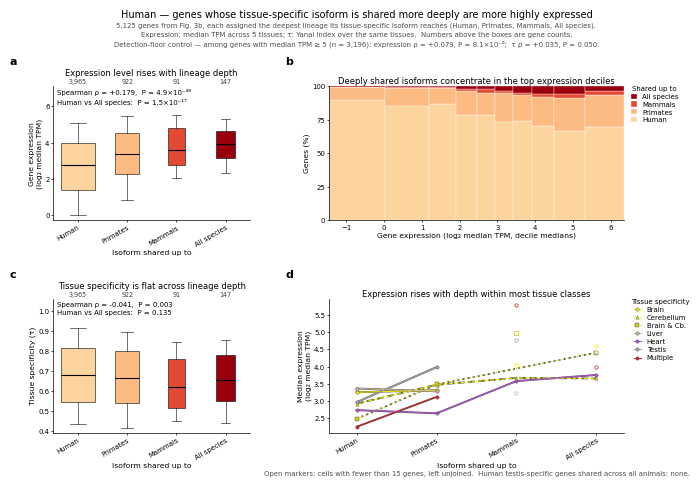

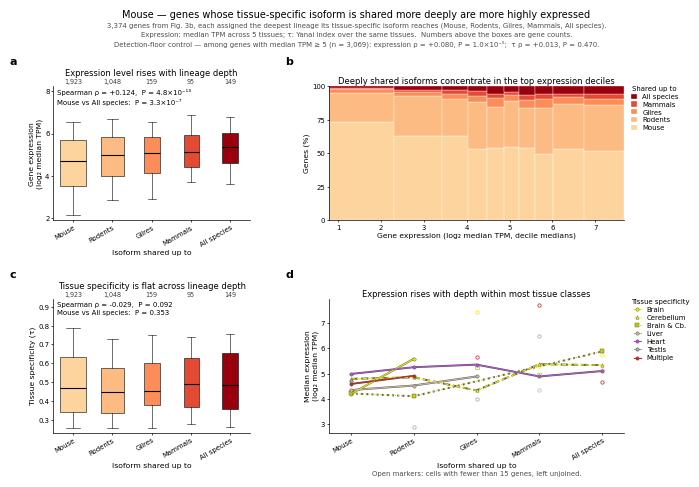

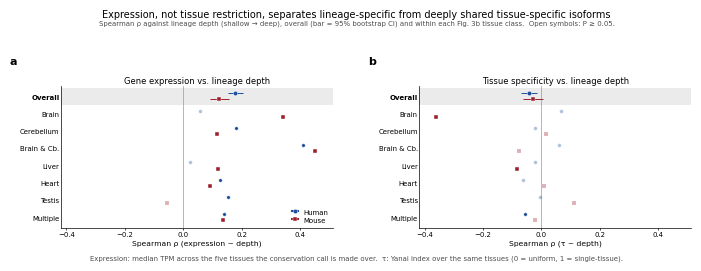

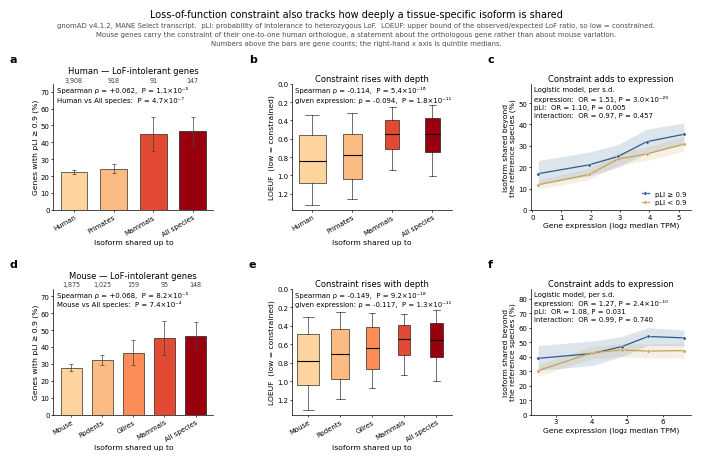

In [12]:
data = load_data()

figs = {}
figs['human']   = draw_species_figure(data['human'])
figs['mouse']   = draw_species_figure(data['mouse'])
figs['summary']    = draw_summary_figure(data)
figs['constraint'] = draw_constraint_figure(data)

for name, fig in figs.items():
    stem = f'SFigure3_expression_{name}'
    for ext, kw in (('png', dict(dpi=400)), ('pdf', {}), ('svg', {})):
        fig.savefig(os.path.join(FIG_DIR, f'{stem}.{ext}'),
                    facecolor='white', **kw)
    print(f'{stem:34s} {PAGE_W:.0f} x {fig.get_size_inches()[1] * 25.4:.1f} mm'
          f'  -> {stem}.png/.pdf/.svg')

## Numbers quoted in the figures

Including the per-cell gene counts behind panel d, which explain where its lines stop.

In [13]:
for sp in ('human', 'mouse'):
    res = data[sp]
    print(f'\n===== {SPECIES_TITLE[sp]} '
          f'({len(res["table"]):,} genes) =====')
    for key, label in (('log2_median_tpm_cons', 'log2 median TPM'),
                       ('tau_cons', 'tissue specificity (tau)')):
        s = res[key]
        print(f'\n{label}:  rho = {s["rho"]:+.3f} '
              f'[{s["rho_lo"]:+.3f}, {s["rho_hi"]:+.3f}]  '
              f'{p_text(s["p_rho"])}   Kruskal-Wallis {p_text(s["kw_p"])}   '
              f'extremes {p_text(s["mw_p"])}')
        print(s['summary'].to_string(float_format=lambda x: f'{x:7.3f}'))
    fold = 2 ** (res['log2_median_tpm_cons']['summary']['median'].iloc[-1]
                 - res['log2_median_tpm_cons']['summary']['median'].iloc[0])
    print(f'\ndeepest / shallowest median expression ratio: {fold:.2f}x')

    c = res['constraint']
    print(f'\nLoF constraint (n = {c["n"]:,}; '
          f'{100 * c["shared_frac"]:.1f}% shared beyond the reference species)')
    print(c['pLI_high_frac'][['sum', 'size', 'frac']].to_string(
        float_format=lambda x: f'{x:7.3f}'))
    for col in ('pLI', 'loeuf'):
        pr = c['partial_rho'][col]
        print(f'{col:6s} rho = {c[col]["rho"]:+.3f} {p_text(c[col]["p_rho"])}   '
              f'given expression: rho = {pr["rho"]:+.3f} {p_text(pr["p"])}')
    for key in ('logit', 'logit_loeuf'):
        lg = c[key]
        print(f'logistic model of being shared, {lg["constraint_col"]} '
              f'(pseudo-R² = {lg["prsquared"]:.4f}):')
        for t in lg['terms']:
            print(f'  {t:22s} OR = {np.exp(lg["params"][t]):.3f} '
                  f'[{np.exp(lg["ci_lo"][t]):.3f}, {np.exp(lg["ci_hi"][t]):.3f}]  '
                  f'{p_text(lg["pvalues"][t])}')

    print('\ngenes per (tissue class × lineage) cell, panel d:')
    print(res['strat_expr']['counts'].to_string())


===== Human (5,125 genes) =====

log2 median TPM:  rho = +0.179 [+0.152, +0.205]  P = 4.9×10⁻³⁸   Kruskal-Wallis P = 2.7×10⁻³⁷   extremes P = 1.5×10⁻¹⁷
                n  median     q25     q75
Human only   3965   2.768   1.397   4.008
Primates      922   3.378   2.281   4.529
Mammals        91   3.581   2.751   4.788
All animals   147   3.947   3.175   4.630

tissue specificity (tau):  rho = -0.041 [-0.069, -0.015]  P = 0.003   Kruskal-Wallis P = 0.008   extremes P = 0.135
                n  median     q25     q75
Human only   3965   0.680   0.548   0.816
Primates      922   0.666   0.540   0.802
Mammals        91   0.623   0.513   0.762
All animals   147   0.657   0.549   0.782

deepest / shallowest median expression ratio: 2.26x

LoF constraint (n = 5,064; 22.8% shared beyond the reference species)
              sum  size    frac
conservation                   
Human only    879  3908   0.225
Primates      223   918   0.243
Mammals        41    91   0.451
All animals    69   147   